In [ ]:
import pandas as pd
path = "/content/LA_County_Traffic_Count.csv"

ds = pd.read_csv(path)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
#Check the amount of missing values
print(ds.isnull().sum())

STREETS         0
COUNT_DATE      0
DAY_OF_WEEK     0
TOTAL_VOLUME    0
ESRI_OID        0
dtype: int64


In [ ]:
#Example rows
ds

,STREETS,COUNT_DATE,DAY_OF_WEEK,TOTAL_VOLUME,ESRI_OID
0,ELIZABETH LAKE ROAD N/O DELTA WAY,2026/03/31 00:00:00+00,Tue,10401,1
1,ELIZABETH LAKE ROAD N/O DELTA WAY,2026/04/01 00:00:00+00,Wed,10824,2
2,LEXINGTON DRIVE E/O RAINBOW DRIVE,2026/04/01 00:00:00+00,Wed,108,3
3,DEL MAR BOULEVARD E/O LOTUS AVENUE,2026/03/19 00:00:00+00,Thu,11748,4
4,DEL MAR BOULEVARD E/O LOTUS AVENUE,2026/03/20 00:00:00+00,Fri,11685,5
...,...,...,...,...,...
6631,HICKS AVENUE N/O 3RD STREET,2024/09/29 00:00:00+00,Sun,884,5266
6632,HICKS AVENUE N/O 3RD STREET,2024/09/30 00:00:00+00,Mon,844,5267
6633,ECHELON AVENUE N/O MEADOWSIDE STREET,2024/10/03 00:00:00+00,Thu,4804,997
6634,50TH STREET WEST N/O AVENUE M-12,2024/10/09 00:00:00+00,Wed,11211,5268


In [ ]:
#Statistical summary

#average volume
avgVol = ds["TOTAL_VOLUME"].mean()

#min volume
minVol = ds["TOTAL_VOLUME"].min()

#max volume
maxVol = ds["TOTAL_VOLUME"].max()

#std volume
stdVol = ds["TOTAL_VOLUME"].std()

In [ ]:
print("Average Volume:")
print(avgVol)
print()

print("Min Volume:")
print(minVol)
print()

print("Max Volume:")
print(maxVol)
print()

print("STD Volume")
print(stdVol)
print()

Average Volume:
5098.389391199517

Min Volume:
0

Max Volume:
49085

STD Volume
7492.940075202942



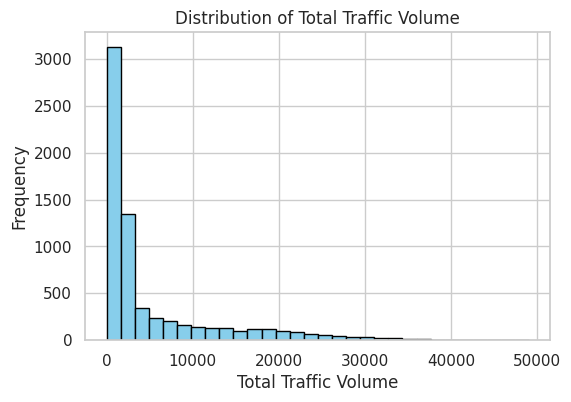

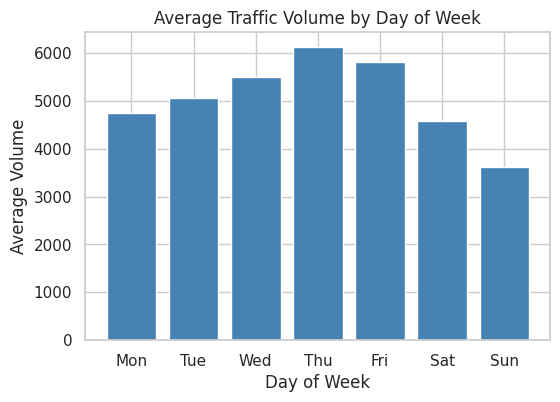

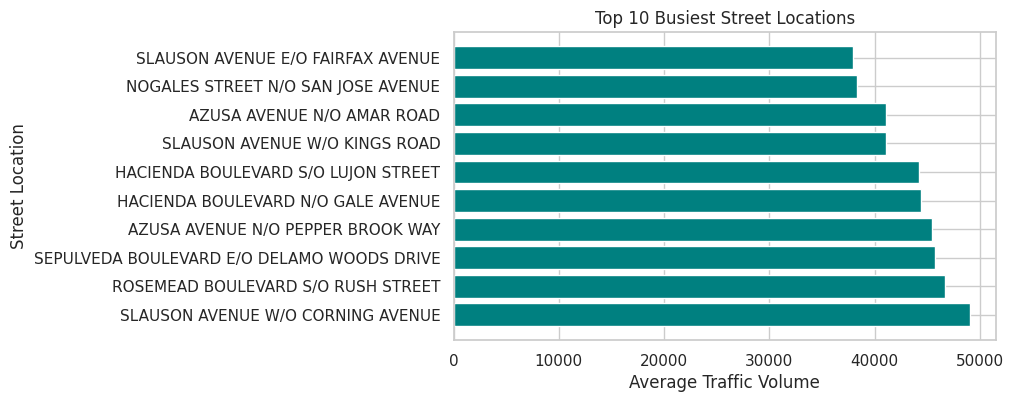

In [ ]:
import matplotlib.pyplot as plt

# 1. Plot Histogram of Total Traffic Volume
plt.figure(figsize=(6, 4))
plt.hist(ds['TOTAL_VOLUME'], bins=30, color='skyblue', edgecolor='black')
plt.title("Distribution of Total Traffic Volume")
plt.xlabel("Total Traffic Volume")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

# 2. Plot Average Traffic Volume by Day of Week
# Group by day and calculate mean volume
day_means = ds.groupby('DAY_OF_WEEK')['TOTAL_VOLUME'].mean()

# Reorder days logically
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
day_means = day_means.reindex(days)

plt.figure(figsize=(6, 4))
plt.bar(day_means.index, day_means.values, color='steelblue')
plt.title("Average Traffic Volume by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Volume")
plt.grid(True)
plt.show()

# 3. Plot Top 10 Busiest Streets
top_streets = ds.groupby('STREETS')['TOTAL_VOLUME'].mean().nlargest(10)

plt.figure(figsize=(7, 4))
plt.barh(top_streets.index, top_streets.values, color='teal')
plt.title("Top 10 Busiest Street Locations")
plt.xlabel("Average Traffic Volume")
plt.ylabel("Street Location")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np

# Make a fresh copy of the dataset
df_clean = ds.copy()

# 1. Drop ESRI_OID column (useless ID column)
df_clean = df_clean.drop(columns=['ESRI_OID'])

# 2. Convert COUNT_DATE to datetime format
df_clean['COUNT_DATE'] = pd.to_datetime(df_clean['COUNT_DATE'])

# Extract Year and Month using basic datetime properties
df_clean['YEAR'] = df_clean['COUNT_DATE'].dt.year
df_clean['MONTH'] = df_clean['COUNT_DATE'].dt.month

# 3. Create Weekend Flag (1 if Saturday/Sunday, 0 if Weekday)
# Saturday is 5, Sunday is 6 in datetime dayofweek
df_clean['IS_WEEKEND'] = (df_clean['COUNT_DATE'].dt.dayofweek >= 5).astype(int)

# 4. Convert DAY_OF_WEEK string to numbers (0=Mon, 6=Sun)
day_dict = {'Mon': 0, 'Tue': 1, 'Wed': 2, 'Thu': 3, 'Fri': 4, 'Sat': 5, 'Sun': 6}
df_clean['DAY_NUM'] = df_clean['DAY_OF_WEEK'].map(day_dict)

# Calculate standard Sine and Cosine for cyclical day features
df_clean['SIN_DAY'] = np.sin(2 * np.pi * df_clean['DAY_NUM'] / 7)
df_clean['COS_DAY'] = np.cos(2 * np.pi * df_clean['DAY_NUM'] / 7)

# 5. Log-Transform TOTAL_VOLUME (adding +1 to avoid log(0))
df_clean['LOG_VOLUME'] = np.log(df_clean['TOTAL_VOLUME'] + 1)

# 6. Standardize LOG_VOLUME using basic formula: (X - mean) / std
vol_mean = df_clean['LOG_VOLUME'].mean()
vol_std = df_clean['LOG_VOLUME'].std()

df_clean['SCALED_LOG_VOLUME'] = (df_clean['LOG_VOLUME'] - vol_mean) / vol_std

# Display sample output rows
df_clean.head()

,STREETS,COUNT_DATE,DAY_OF_WEEK,TOTAL_VOLUME,YEAR,MONTH,IS_WEEKEND,DAY_NUM,SIN_DAY,COS_DAY,LOG_VOLUME,SCALED_LOG_VOLUME
0,ELIZABETH LAKE ROAD N/O DELTA WAY,2026-03-31 00:00:00+00:00,Tue,10401,2026,3,0,1,0.781831,0.623490,9.249753,1.133104
1,ELIZABETH LAKE ROAD N/O DELTA WAY,2026-04-01 00:00:00+00:00,Wed,10824,2026,4,0,2,0.974928,-0.222521,9.289614,1.159001
2,LEXINGTON DRIVE E/O RAINBOW DRIVE,2026-04-01 00:00:00+00:00,Wed,108,2026,4,0,2,0.974928,-0.222521,4.691348,-1.828433
3,DEL MAR BOULEVARD E/O LOTUS AVENUE,2026-03-19 00:00:00+00:00,Thu,11748,2026,3,0,3,0.433884,-0.900969,9.371523,1.212217
4,DEL MAR BOULEVARD E/O LOTUS AVENUE,2026-03-20 00:00:00+00:00,Fri,11685,2026,3,0,4,-0.433884,-0.900969,9.366147,1.208724
